In [2]:
# MzaziCare
# Synthetic Data Generation and ML Prototype
#
# Project:
# An Explainable Knowledge Graph-Enhanced
# Hybrid Recommender for Elderly Home Caregiver Matching
#
# Purpose:
# 1. Generate synthetic caregiver/client data
# 2. Generate relationship data for the Knowledge Graph
# 3. Generate booking history
# 4. Prepare ML training data
# 5. Train and evaluate Random Forest
# 6. Apply SHAP for explainability

In [3]:
!pip install -q pandas numpy scikit-learn shap matplotlib seaborn joblib

In [4]:
import pandas as pd
import numpy as np
import random
import os
import joblib
import shap
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime, timedelta

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Reproducibility
RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

print("All libraries loaded successfully.")

All libraries loaded successfully.


In [5]:
# ============================================================
# MZAZICARE SYNTHETIC DATA PARAMETERS
# ============================================================

NUM_CAREGIVERS = 100
NUM_CLIENTS = 200

SKILLS = [
    "Elderly Care",
    "Medication Support",
    "Dementia Care",
    "Mobility Assistance",
    "First Aid",
    "Companionship",
    "Personal Care",
    "Nutrition Support",
    "Health Monitoring",
    "Physiotherapy Assistance"
]

SERVICES = [
    "Companionship",
    "Personal Care",
    "Medication Support",
    "Mobility Assistance",
    "Dementia Care",
    "Meal Preparation",
    "Household Assistance",
    "Health Monitoring"
]

LOCATIONS = [
    "Langata",
    "Kilimani",
    "Nairobi West",
    "Westlands",
    "Karen",
    "Lavington",
    "Kileleshwa",
    "South B",
    "Parklands",
    "Runda"
]

CARE_LEVELS = [
    "Low",
    "Medium",
    "High"
]

AVAILABILITY_TYPES = [
    "Full-time",
    "Part-time",
    "Weekdays",
    "Weekends"
]

GENDERS = [
    "Female",
    "Male"
]

print(f"Caregivers: {NUM_CAREGIVERS}")
print(f"Clients: {NUM_CLIENTS}")
print(f"Skills: {len(SKILLS)}")
print(f"Services: {len(SERVICES)}")
print(f"Locations: {len(LOCATIONS)}")

Caregivers: 100
Clients: 200
Skills: 10
Services: 8
Locations: 10


In [6]:
# ============================================================
# SERVICE -> RELEVANT SKILLS
# ============================================================

SERVICE_SKILL_MAP = {
    "Companionship": [
        "Companionship",
        "Elderly Care"
    ],

    "Personal Care": [
        "Personal Care",
        "Elderly Care"
    ],

    "Medication Support": [
        "Medication Support",
        "Health Monitoring"
    ],

    "Mobility Assistance": [
        "Mobility Assistance",
        "Physiotherapy Assistance"
    ],

    "Dementia Care": [
        "Dementia Care",
        "Elderly Care"
    ],

    "Meal Preparation": [
        "Nutrition Support",
        "Elderly Care"
    ],

    "Household Assistance": [
        "Elderly Care",
        "Personal Care"
    ],

    "Health Monitoring": [
        "Health Monitoring",
        "First Aid"
    ]
}

print("Service-skill relationships defined.")

for service, required_skills in SERVICE_SKILL_MAP.items():
    print(f"{service}: {required_skills}")

Service-skill relationships defined.
Companionship: ['Companionship', 'Elderly Care']
Personal Care: ['Personal Care', 'Elderly Care']
Medication Support: ['Medication Support', 'Health Monitoring']
Mobility Assistance: ['Mobility Assistance', 'Physiotherapy Assistance']
Dementia Care: ['Dementia Care', 'Elderly Care']
Meal Preparation: ['Nutrition Support', 'Elderly Care']
Household Assistance: ['Elderly Care', 'Personal Care']
Health Monitoring: ['Health Monitoring', 'First Aid']


In [7]:
# ============================================================
# SYNTHETIC DISTANCE MATRIX
# ============================================================

distance_matrix = {}

for location_a in LOCATIONS:
    distance_matrix[location_a] = {}

    for location_b in LOCATIONS:

        if location_a == location_b:
            distance = 0.5
        else:
            distance = round(
                np.random.uniform(2, 15),
                1
            )

        distance_matrix[location_a][location_b] = distance

print("Distance matrix created.")

print(
    "Example:",
    distance_matrix["Langata"]["Kilimani"],
    "km"
)

Distance matrix created.
Example: 6.9 km


In [8]:
# ============================================================
# GENERATE CAREGIVERS
# ============================================================

caregivers = []

for i in range(1, NUM_CAREGIVERS + 1):

    caregiver = {
        "caregiver_id": f"CG{i:03d}",
        "age": random.randint(24, 55),
        "gender": random.choice(GENDERS),
        "experience_years": random.randint(1, 15),
        "rating": round(
            np.random.uniform(3.0, 5.0),
            1
        ),
        "location": random.choice(LOCATIONS),
        "availability": random.choice(
            AVAILABILITY_TYPES
        )
    }

    caregivers.append(caregiver)

caregivers_df = pd.DataFrame(caregivers)

print("Caregivers generated:", len(caregivers_df))

display(caregivers_df.head(10))

Caregivers generated: 100


,caregiver_id,age,gender,experience_years,rating,location,availability
0,CG001,31,Female,12,3.2,Karen,Part-time
1,CG002,38,Female,12,4.4,Kilimani,Full-time
2,CG003,51,Female,1,4.5,Kilimani,Part-time
3,CG004,38,Female,9,4.1,Westlands,Weekends
4,CG005,38,Male,10,4.5,Karen,Full-time
5,CG006,34,Male,6,4.0,Karen,Part-time
6,CG007,37,Male,2,4.0,Kilimani,Weekends
7,CG008,30,Male,14,3.9,Lavington,Weekdays
8,CG009,26,Male,9,3.1,Kilimani,Weekends
9,CG010,29,Male,14,3.2,Runda,Weekdays


In [9]:
# ============================================================
# CAREGIVER -> HAS_SKILL -> SKILL
# ============================================================

caregiver_skills = []

for caregiver_id in caregivers_df["caregiver_id"]:

    selected_skills = random.sample(
        SKILLS,
        random.randint(2, 5)
    )

    for skill in selected_skills:

        caregiver_skills.append({
            "caregiver_id": caregiver_id,
            "skill": skill
        })

caregiver_skills_df = pd.DataFrame(
    caregiver_skills
)

print(
    "Caregiver-skill relationships:",
    len(caregiver_skills_df)
)

display(caregiver_skills_df.head(15))

Caregiver-skill relationships: 368


,caregiver_id,skill
0,CG001,Nutrition Support
1,CG001,Dementia Care
2,CG002,Health Monitoring
3,CG002,Physiotherapy Assistance
4,CG002,Companionship
5,CG002,Personal Care
6,CG002,Mobility Assistance
7,CG003,Health Monitoring
8,CG003,Nutrition Support
9,CG003,Dementia Care


In [10]:
# ============================================================
# CAREGIVER -> PROVIDES -> SERVICE
# ============================================================

caregiver_services = []

for _, caregiver in caregivers_df.iterrows():

    caregiver_id = caregiver["caregiver_id"]

    caregiver_skill_list = caregiver_skills_df[
        caregiver_skills_df["caregiver_id"] == caregiver_id
    ]["skill"].tolist()

    possible_services = []

    for service, required_skills in SERVICE_SKILL_MAP.items():

        if any(
            skill in caregiver_skill_list
            for skill in required_skills
        ):
            possible_services.append(service)

    # Ensure every caregiver provides at least 2 services
    if len(possible_services) < 2:
        possible_services = random.sample(
            SERVICES,
            2
        )

    selected_services = random.sample(
        possible_services,
        min(
            len(possible_services),
            random.randint(2, 4)
        )
    )

    for service in selected_services:

        caregiver_services.append({
            "caregiver_id": caregiver_id,
            "service": service
        })

caregiver_services_df = pd.DataFrame(
    caregiver_services
)

print(
    "Caregiver-service relationships:",
    len(caregiver_services_df)
)

display(caregiver_services_df.head(15))

Caregiver-service relationships: 288


,caregiver_id,service
0,CG001,Meal Preparation
1,CG001,Dementia Care
2,CG002,Health Monitoring
3,CG002,Mobility Assistance
4,CG002,Companionship
5,CG002,Medication Support
6,CG003,Medication Support
7,CG003,Mobility Assistance
8,CG004,Personal Care
9,CG004,Household Assistance


In [11]:
# ============================================================
# GENERATE CLIENTS
# ============================================================

clients = []

for i in range(1, NUM_CLIENTS + 1):

    client = {
        "client_id": f"CL{i:03d}",
        "age": random.randint(60, 95),
        "gender": random.choice(GENDERS),
        "location": random.choice(LOCATIONS),
        "care_level": random.choice(CARE_LEVELS)
    }

    clients.append(client)

clients_df = pd.DataFrame(clients)

print("Clients generated:", len(clients_df))

display(clients_df.head(10))

Clients generated: 200


,client_id,age,gender,location,care_level
0,CL001,91,Male,Kileleshwa,Medium
1,CL002,73,Female,Lavington,Medium
2,CL003,67,Male,Runda,Medium
3,CL004,93,Male,Langata,Low
4,CL005,85,Female,Langata,Low
5,CL006,79,Female,Nairobi West,Medium
6,CL007,78,Male,Kilimani,Low
7,CL008,91,Male,Nairobi West,Low
8,CL009,84,Female,Parklands,High
9,CL010,82,Female,Kileleshwa,High


In [12]:
# ============================================================
# CLIENT -> REQUIRES -> SERVICE
# ============================================================

client_needs = []

for client_id in clients_df["client_id"]:

    selected_services = random.sample(
        SERVICES,
        random.randint(1, 3)
    )

    for service in selected_services:

        client_needs.append({
            "client_id": client_id,
            "service": service
        })

client_needs_df = pd.DataFrame(
    client_needs
)

print(
    "Client-service relationships:",
    len(client_needs_df)
)

display(client_needs_df.head(15))

Client-service relationships: 388


,client_id,service
0,CL001,Health Monitoring
1,CL001,Meal Preparation
2,CL002,Dementia Care
3,CL003,Dementia Care
4,CL003,Meal Preparation
5,CL004,Personal Care
6,CL005,Mobility Assistance
7,CL005,Dementia Care
8,CL005,Meal Preparation
9,CL006,Companionship


In [13]:
# ============================================================
# INSPECT ONE CLIENT'S REQUIREMENTS
# ============================================================

example_client = "CL001"

client_info = clients_df[
    clients_df["client_id"] == example_client
]

client_requirements = client_needs_df[
    client_needs_df["client_id"] == example_client
]

print("CLIENT")
display(client_info)

print("REQUIRED SERVICES")
display(client_requirements)

CLIENT


,client_id,age,gender,location,care_level
0,CL001,91,Male,Kileleshwa,Medium


REQUIRED SERVICES


,client_id,service
0,CL001,Health Monitoring
1,CL001,Meal Preparation


In [14]:
example_caregiver = "CG001"

caregiver_info = caregivers_df[
    caregivers_df["caregiver_id"] == example_caregiver
]

caregiver_skill_info = caregiver_skills_df[
    caregiver_skills_df["caregiver_id"] == example_caregiver
]

caregiver_service_info = caregiver_services_df[
    caregiver_services_df["caregiver_id"] == example_caregiver
]

print("CAREGIVER")
display(caregiver_info)

print("SKILLS")
display(caregiver_skill_info)

print("SERVICES")
display(caregiver_service_info)

CAREGIVER


,caregiver_id,age,gender,experience_years,rating,location,availability
0,CG001,31,Female,12,3.2,Karen,Part-time


SKILLS


,caregiver_id,skill
0,CG001,Nutrition Support
1,CG001,Dementia Care


SERVICES


,caregiver_id,service
0,CG001,Meal Preparation
1,CG001,Dementia Care


ML training data

In [15]:
# ============================================================
# CREATE CLIENT-CAREGIVER CANDIDATE PAIRS
# ============================================================

training_rows = []

for _, client in clients_df.iterrows():

    client_id = client["client_id"]
    client_location = client["location"]
    care_level = client["care_level"]

    required_services = client_needs_df[
        client_needs_df["client_id"] == client_id
    ]["service"].tolist()

    for service in required_services:

        required_skills = SERVICE_SKILL_MAP[service]

        for _, caregiver in caregivers_df.iterrows():

            caregiver_id = caregiver["caregiver_id"]

            caregiver_location = caregiver["location"]

            caregiver_skills_list = caregiver_skills_df[
                caregiver_skills_df["caregiver_id"] == caregiver_id
            ]["skill"].tolist()

            caregiver_services_list = caregiver_services_df[
                caregiver_services_df["caregiver_id"] == caregiver_id
            ]["service"].tolist()

            # -----------------------------
            # SERVICE MATCH
            # -----------------------------

            service_match = int(
                service in caregiver_services_list
            )

            # -----------------------------
            # SKILL MATCH
            # -----------------------------

            skill_match = int(
                any(
                    skill in caregiver_skills_list
                    for skill in required_skills
                )
            )

            # -----------------------------
            # LOCATION
            # -----------------------------

            distance_km = distance_matrix[
                client_location
            ][
                caregiver_location
            ]

            location_match = int(
                distance_km <= 5
            )

            # -----------------------------
            # AVAILABILITY
            # -----------------------------

            availability_match = int(
                caregiver["availability"]
                in ["Full-time", "Weekdays"]
            )

            # -----------------------------
            # EXPERIENCE
            # -----------------------------

            experience = caregiver[
                "experience_years"
            ]

            # -----------------------------
            # RATING
            # -----------------------------

            rating = caregiver["rating"]

            # -----------------------------
            # CARE LEVEL
            # -----------------------------

            if care_level == "High":
                experience_match = int(
                    experience >= 5
                )
            elif care_level == "Medium":
                experience_match = int(
                    experience >= 3
                )
            else:
                experience_match = 1

            training_rows.append({

                "client_id": client_id,

                "caregiver_id": caregiver_id,

                "service": service,

                "client_location": client_location,

                "caregiver_location": caregiver_location,

                "care_level": care_level,

                "service_match": service_match,

                "skill_match": skill_match,

                "location_match": location_match,

                "availability_match":
                    availability_match,

                "experience_years":
                    experience,

                "experience_match":
                    experience_match,

                "rating": rating,

                "distance_km":
                    distance_km
            })

candidate_df = pd.DataFrame(
    training_rows
)

print(
    "Candidate rows created:",
    len(candidate_df)
)

display(candidate_df.head(10))

Candidate rows created: 38800


,client_id,caregiver_id,service,client_location,caregiver_location,care_level,service_match,skill_match,location_match,availability_match,experience_years,experience_match,rating,distance_km
0,CL001,CG001,Health Monitoring,Kileleshwa,Karen,Medium,0,0,1,0,12,1,3.2,2.6
1,CL001,CG002,Health Monitoring,Kileleshwa,Kilimani,Medium,1,1,0,1,12,1,4.4,14.0
2,CL001,CG003,Health Monitoring,Kileleshwa,Kilimani,Medium,0,1,0,0,1,0,4.5,14.0
3,CL001,CG004,Health Monitoring,Kileleshwa,Westlands,Medium,0,1,1,0,9,1,4.1,4.5
4,CL001,CG005,Health Monitoring,Kileleshwa,Karen,Medium,1,1,1,1,10,1,4.5,2.6
5,CL001,CG006,Health Monitoring,Kileleshwa,Karen,Medium,1,1,1,0,6,1,4.0,2.6
6,CL001,CG007,Health Monitoring,Kileleshwa,Kilimani,Medium,0,0,0,0,2,0,4.0,14.0
7,CL001,CG008,Health Monitoring,Kileleshwa,Lavington,Medium,0,0,0,1,14,1,3.9,6.2
8,CL001,CG009,Health Monitoring,Kileleshwa,Kilimani,Medium,0,0,0,0,9,1,3.1,14.0
9,CL001,CG010,Health Monitoring,Kileleshwa,Runda,Medium,0,1,0,1,14,1,3.2,12.8


In [16]:
# ============================================================
# GENERATE SYNTHETIC SUITABILITY LABEL
# ============================================================

def generate_suitability(row):

    score = 0

    # Strongest factors
    score += row["service_match"] * 3.0
    score += row["skill_match"] * 3.0

    # Availability
    score += row["availability_match"] * 1.5

    # Location
    score += row["location_match"] * 1.5

    # Experience
    score += min(
        row["experience_years"] / 10,
        1
    ) * 1.5

    # Rating
    score += (
        (row["rating"] - 3) / 2
    ) * 1.5

    # Experience appropriate to care level
    score += row["experience_match"] * 1.5

    # Distance penalty
    score -= min(
        row["distance_km"] / 20,
        1
    ) * 2

    # Add synthetic noise
    score += np.random.normal(
        0,
        1.0
    )

    # Convert score into suitability
    probability = 1 / (
        1 + np.exp(-(
            score - 6
        ))
    )

    return int(
        np.random.random() < probability
    )


candidate_df["suitable"] = candidate_df.apply(
    generate_suitability,
    axis=1
)

print(
    "Suitability labels generated."
)

print(
    candidate_df["suitable"].value_counts()
)

print(
    "\nSuitability proportions:"
)

print(
    candidate_df["suitable"].value_counts(
        normalize=True
    )
)

Suitability labels generated.
suitable
1    21074
0    17726
Name: count, dtype: int64

Suitability proportions:
suitable
1    0.543144
0    0.456856
Name: proportion, dtype: float64


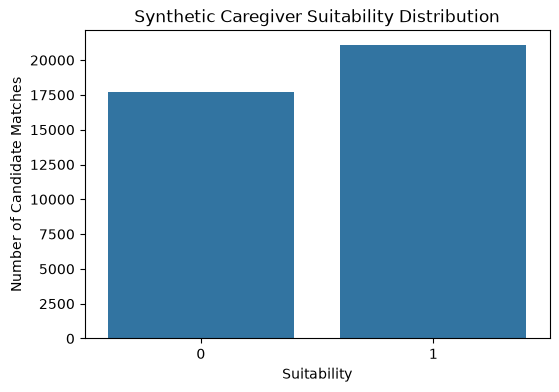

In [17]:
# ============================================================
# CHECK CLASS DISTRIBUTION
# ============================================================

plt.figure(figsize=(6, 4))

sns.countplot(
    data=candidate_df,
    x="suitable"
)

plt.title(
    "Synthetic Caregiver Suitability Distribution"
)

plt.xlabel(
    "Suitability"
)

plt.ylabel(
    "Number of Candidate Matches"
)

plt.show()

In [18]:
# ============================================================
# ML FEATURES
# ============================================================

FEATURES = [
    "service_match",
    "skill_match",
    "location_match",
    "availability_match",
    "experience_years",
    "experience_match",
    "rating",
    "distance_km"
]

TARGET = "suitable"

X = candidate_df[FEATURES]

y = candidate_df[TARGET]

print("Features:")
print(FEATURES)

print("\nTarget:")
print(TARGET)

print("\nX shape:")
print(X.shape)

print("\ny shape:")
print(y.shape)

Features:
['service_match', 'skill_match', 'location_match', 'availability_match', 'experience_years', 'experience_match', 'rating', 'distance_km']

Target:
suitable

X shape:
(38800, 8)

y shape:
(38800,)


In [19]:
# ============================================================
# TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 31040
Testing rows: 7760


In [20]:
# ============================================================
# RANDOM FOREST MODEL
# ============================================================

model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=RANDOM_STATE,
    class_weight="balanced"
)

model.fit(
    X_train,
    y_train
)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [21]:
# ============================================================
# MODEL PREDICTIONS
# ============================================================

y_pred = model.predict(X_test)

y_probability = model.predict_proba(
    X_test
)[:, 1]

print("Predictions generated.")

print(
    "First 10 predictions:",
    y_pred[:10]
)

Predictions generated.
First 10 predictions: [0 0 0 1 1 0 0 1 1 1]


In [22]:
# ============================================================
# MODEL EVALUATION
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_probability
)

print("=" * 50)
print("MZAZICARE RANDOM FOREST EVALUATION")
print("=" * 50)

print(f"Accuracy :  {accuracy:.4f}")
print(f"Precision:  {precision:.4f}")
print(f"Recall   :  {recall:.4f}")
print(f"F1-score :  {f1:.4f}")
print(f"ROC-AUC  :  {roc_auc:.4f}")

MZAZICARE RANDOM FOREST EVALUATION
Accuracy :  0.8330
Precision:  0.8628
Recall   :  0.8235
F1-score :  0.8427
ROC-AUC  :  0.9096


In [23]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Not Suitable",
            "Suitable"
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

Not Suitable       0.80      0.84      0.82      3545
    Suitable       0.86      0.82      0.84      4215

    accuracy                           0.83      7760
   macro avg       0.83      0.83      0.83      7760
weighted avg       0.83      0.83      0.83      7760



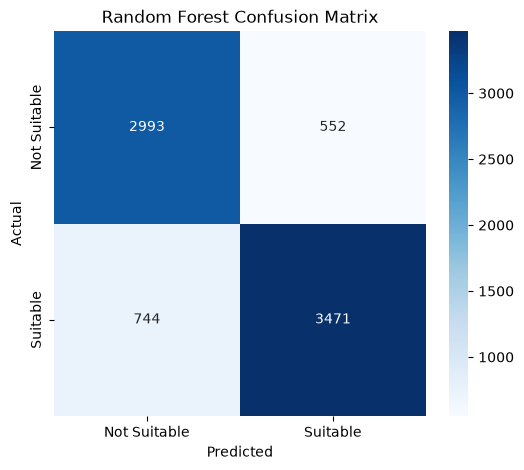

In [24]:
# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Not Suitable",
        "Suitable"
    ],
    yticklabels=[
        "Not Suitable",
        "Suitable"
    ]
)

plt.title(
    "Random Forest Confusion Matrix"
)

plt.xlabel(
    "Predicted"
)

plt.ylabel(
    "Actual"
)

plt.show()

In [25]:
# ============================================================
# FEATURE IMPORTANCE
# ============================================================

feature_importance = pd.DataFrame({
    "feature": FEATURES,
    "importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
)

display(feature_importance)

,feature,importance
1,skill_match,0.374195
0,service_match,0.315979
7,distance_km,0.099805
4,experience_years,0.056541
6,rating,0.040950
3,availability_match,0.040310
2,location_match,0.040064
5,experience_match,0.032157


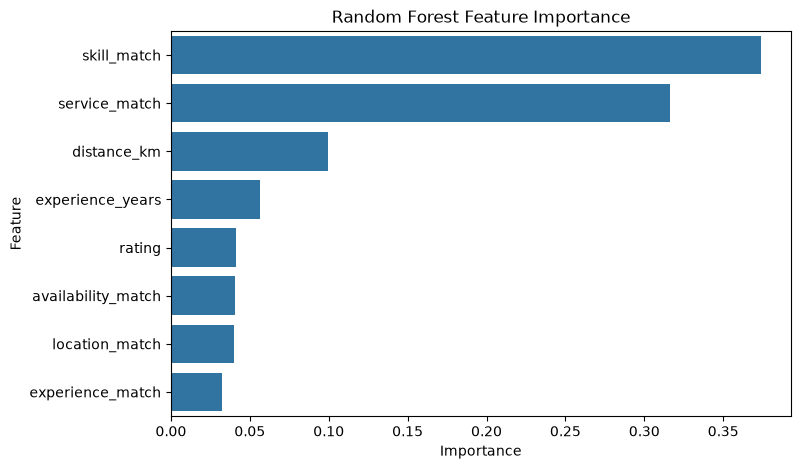

In [26]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=feature_importance,
    x="importance",
    y="feature"
)

plt.title(
    "Random Forest Feature Importance"
)

plt.xlabel(
    "Importance"
)

plt.ylabel(
    "Feature"
)

plt.show()

In [27]:
# ============================================================
# SHAP EXPLAINABILITY
# ============================================================

explainer = shap.TreeExplainer(
    model
)

shap_values = explainer.shap_values(
    X_test
)

print("SHAP values generated.")

KeyboardInterrupt: 

In [ ]:
print(
    type(shap_values)
)

if isinstance(shap_values, list):
    print(
        "Number of SHAP output arrays:",
        len(shap_values)
    )

    for i, values in enumerate(shap_values):
        print(
            f"Class {i} shape:",
            values.shape
        )

else:
    print(
        "SHAP array shape:",
        shap_values.shape
    )

<class 'numpy.ndarray'>
SHAP array shape: (7760, 8, 2)


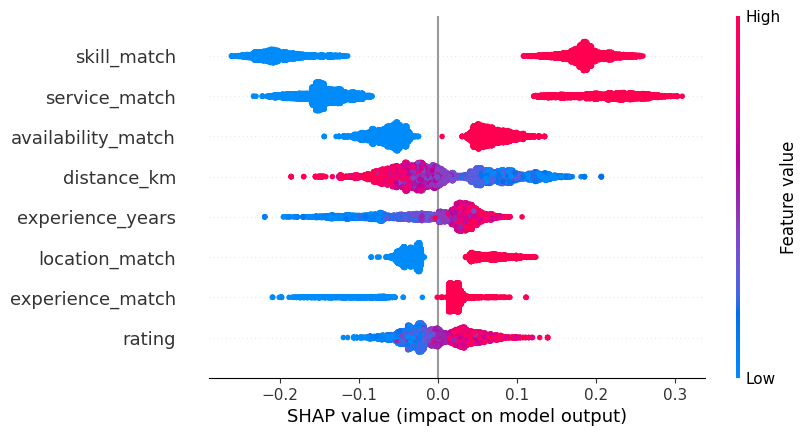

In [ ]:
# ============================================================
# SHAP SUMMARY
# ============================================================

try:

    shap_exp = shap.Explanation(
        values=(
            shap_values[:, :, 1]
            if len(shap_values.shape) == 3
            else shap_values
        ),
        base_values=explainer.expected_value[1]
            if isinstance(
                explainer.expected_value,
                np.ndarray
            )
            else explainer.expected_value,
        data=X_test,
        feature_names=FEATURES
    )

    shap.plots.beeswarm(
        shap_exp,
        max_display=10
    )

except Exception as e:

    print(
        "Using alternative SHAP plotting method."
    )

    if isinstance(shap_values, list):

        shap.summary_plot(
            shap_values[1],
            X_test,
            feature_names=FEATURES
        )

    else:

        shap.summary_plot(
            shap_values,
            X_test,
            feature_names=FEATURES
        )

TEST RECOMMENDATION

In [ ]:
# ============================================================
# RECOMMENDATION TEST
# ============================================================

TEST_CLIENT = "CL001"

client_info = clients_df[
    clients_df["client_id"] == TEST_CLIENT
].iloc[0]

client_requirements = client_needs_df[
    client_needs_df["client_id"] == TEST_CLIENT
]["service"].tolist()

print("Client:", TEST_CLIENT)
print("Location:", client_info["location"])
print("Care level:", client_info["care_level"])
print("Required services:", client_requirements)

Client: CL001
Location: Kileleshwa
Care level: Medium
Required services: ['Health Monitoring', 'Meal Preparation']


In [ ]:
client_candidates = candidate_df[
    candidate_df["client_id"] == TEST_CLIENT
].copy()

print(
    "Candidate rows:",
    len(client_candidates)
)

display(
    client_candidates.head()
)

Candidate rows: 200


,client_id,caregiver_id,service,client_location,caregiver_location,care_level,service_match,skill_match,location_match,availability_match,experience_years,experience_match,rating,distance_km,suitable
0,CL001,CG001,Health Monitoring,Kileleshwa,Karen,Medium,0,0,1,0,12,1,3.2,2.6,0
1,CL001,CG002,Health Monitoring,Kileleshwa,Kilimani,Medium,1,1,0,1,12,1,4.4,14.0,1
2,CL001,CG003,Health Monitoring,Kileleshwa,Kilimani,Medium,0,1,0,0,1,0,4.5,14.0,0
3,CL001,CG004,Health Monitoring,Kileleshwa,Westlands,Medium,0,1,1,0,9,1,4.1,4.5,1
4,CL001,CG005,Health Monitoring,Kileleshwa,Karen,Medium,1,1,1,1,10,1,4.5,2.6,1


In [ ]:
client_X = client_candidates[
    FEATURES
]

client_candidates[
    "suitability_probability"
] = model.predict_proba(
    client_X
)[:, 1]

client_candidates[
    "prediction"
] = model.predict(
    client_X
)

In [ ]:
recommendations = client_candidates.sort_values(
    by="suitability_probability",
    ascending=False
)

recommendations[
    [
        "caregiver_id",
        "service",
        "service_match",
        "skill_match",
        "location_match",
        "availability_match",
        "experience_years",
        "rating",
        "distance_km",
        "suitability_probability"
    ]
].head(10)

,caregiver_id,service,service_match,skill_match,location_match,availability_match,experience_years,rating,distance_km,suitability_probability
28,CG029,Health Monitoring,1,1,1,1,13,4.8,3.2,0.999821
135,CG036,Meal Preparation,1,1,1,1,4,3.9,4.5,0.999815
168,CG069,Meal Preparation,1,1,1,1,6,3.5,3.2,0.999670
71,CG072,Health Monitoring,1,1,1,1,7,4.3,3.2,0.999618
86,CG087,Health Monitoring,1,1,1,1,6,4.4,0.5,0.999601
186,CG087,Meal Preparation,1,1,1,1,6,4.4,0.5,0.999601
174,CG075,Meal Preparation,1,1,1,0,15,3.2,4.5,0.999552
32,CG033,Health Monitoring,1,1,1,1,9,3.6,3.2,0.998848
126,CG027,Meal Preparation,1,1,1,0,12,4.6,2.6,0.998561
150,CG051,Meal Preparation,1,1,1,0,5,4.9,0.5,0.998244


In [ ]:
top_recommendation = recommendations.iloc[0]

print("=" * 60)
print("MZAZICARE CAREGIVER RECOMMENDATION")
print("=" * 60)

print(
    f"Client: {TEST_CLIENT}"
)

print(
    f"Recommended Caregiver: "
    f"{top_recommendation['caregiver_id']}"
)

print(
    f"Service: "
    f"{top_recommendation['service']}"
)

print(
    f"Suitability Probability: "
    f"{top_recommendation['suitability_probability']:.2%}"
)

print(
    f"Skill Match: "
    f"{top_recommendation['skill_match']}"
)

print(
    f"Service Match: "
    f"{top_recommendation['service_match']}"
)

print(
    f"Location Match: "
    f"{top_recommendation['location_match']}"
)

print(
    f"Experience: "
    f"{top_recommendation['experience_years']} years"
)

print(
    f"Rating: "
    f"{top_recommendation['rating']}"
)

print(
    f"Distance: "
    f"{top_recommendation['distance_km']} km"
)

MZAZICARE CAREGIVER RECOMMENDATION
Client: CL001
Recommended Caregiver: CG029
Service: Health Monitoring
Suitability Probability: 99.98%
Skill Match: 1
Service Match: 1
Location Match: 1
Experience: 13 years
Rating: 4.8
Distance: 3.2 km


explaining SHAP for recommendations

In [ ]:
top_features = top_recommendation[
    FEATURES
].to_frame().T

display(top_features)

,service_match,skill_match,location_match,availability_match,experience_years,experience_match,rating,distance_km
28,1,1,1,1,13,1,4.8,3.2


In [ ]:
top_shap_values = explainer.shap_values(
    top_features
)

In [ ]:
if isinstance(top_shap_values, list):

    values_for_positive_class = (
        top_shap_values[1][0]
    )

else:

    if len(top_shap_values.shape) == 3:

        values_for_positive_class = (
            top_shap_values[0, :, 1]
        )

    else:

        values_for_positive_class = (
            top_shap_values[0]
        )

shap_explanation = pd.DataFrame({
    "feature": FEATURES,
    "feature_value": top_features.iloc[0].values,
    "shap_value": values_for_positive_class
})

shap_explanation[
    "absolute_shap"
] = shap_explanation[
    "shap_value"
].abs()

shap_explanation = shap_explanation.sort_values(
    by="absolute_shap",
    ascending=False
)

display(
    shap_explanation[
        [
            "feature",
            "feature_value",
            "shap_value"
        ]
    ]
)

,feature,feature_value,shap_value
1,skill_match,1,0.155486
0,service_match,1,0.127020
7,distance_km,3.2,0.054982
3,availability_match,1,0.043329
2,location_match,1,0.042787
6,rating,4.8,0.032608
4,experience_years,13,0.028176
5,experience_match,1,0.015491


In [ ]:
# ============================================================
# HUMAN-READABLE SHAP EXPLANATION
# ============================================================

positive_factors = shap_explanation[
    shap_explanation["shap_value"] > 0
].head(5)

negative_factors = shap_explanation[
    shap_explanation["shap_value"] < 0
].head(5)

print("WHY THIS CAREGIVER WAS RECOMMENDED")
print("=" * 50)

print("\nFactors supporting the recommendation:")

for _, row in positive_factors.iterrows():

    print(
        f"✓ {row['feature']} "
        f"contributed positively "
        f"(SHAP: {row['shap_value']:.3f})"
    )

print("\nFactors reducing suitability:")

for _, row in negative_factors.iterrows():

    print(
        f"• {row['feature']} "
        f"reduced suitability "
        f"(SHAP: {row['shap_value']:.3f})"
    )

WHY THIS CAREGIVER WAS RECOMMENDED

Factors supporting the recommendation:
✓ skill_match contributed positively (SHAP: 0.155)
✓ service_match contributed positively (SHAP: 0.127)
✓ distance_km contributed positively (SHAP: 0.055)
✓ availability_match contributed positively (SHAP: 0.043)
✓ location_match contributed positively (SHAP: 0.043)

Factors reducing suitability:


In [ ]:
# ============================================================
# MODEL VALIDATION CHECK
# ============================================================

assert len(X_train) > 0
assert len(X_test) > 0

assert len(y_train) > 0
assert len(y_test) > 0

assert len(np.unique(y_train)) == 2
assert len(np.unique(y_test)) == 2

assert 0 <= accuracy <= 1
assert 0 <= precision <= 1
assert 0 <= recall <= 1
assert 0 <= f1 <= 1

print("Basic model validation checks passed.")

Basic model validation checks passed.


In [ ]:
assert len(recommendations) > 0

assert (
    "suitability_probability"
    in recommendations.columns
)

assert (
    recommendations[
        "suitability_probability"
    ].between(0, 1).all()
)

print(
    "Recommendation pipeline validation passed."
)

Recommendation pipeline validation passed.


In [ ]:
# ============================================================
# SAVE ONLY AFTER VALIDATION
# ============================================================

OUTPUT_DIR = "/content/mzazicare_data"

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

print(
    f"Output directory created: {OUTPUT_DIR}"
)

Output directory created: /content/mzazicare_data


In [ ]:
caregivers_df.to_csv(
    f"{OUTPUT_DIR}/caregivers.csv",
    index=False
)

clients_df.to_csv(
    f"{OUTPUT_DIR}/clients.csv",
    index=False
)

caregiver_skills_df.to_csv(
    f"{OUTPUT_DIR}/caregiver_skills.csv",
    index=False
)

caregiver_services_df.to_csv(
    f"{OUTPUT_DIR}/caregiver_services.csv",
    index=False
)

client_needs_df.to_csv(
    f"{OUTPUT_DIR}/client_needs.csv",
    index=False
)

In [ ]:
candidate_df.to_csv(
    f"{OUTPUT_DIR}/recommendation_training.csv",
    index=False
)

print(
    "Training dataset saved."
)

Training dataset saved.


In [ ]:
MODEL_PATH = (
    f"{OUTPUT_DIR}/caregiver_random_forest.pkl"
)

joblib.dump(
    model,
    MODEL_PATH
)

print(
    f"Model saved to: {MODEL_PATH}"
)

Model saved to: /content/mzazicare_data/caregiver_random_forest.pkl


In [ ]:
evaluation_results = pd.DataFrame({
    "metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "value": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

evaluation_results.to_csv(
    f"{OUTPUT_DIR}/model_evaluation.csv",
    index=False
)

display(evaluation_results)

,metric,value
0,Accuracy,0.831830
1,Precision,0.861042
2,Recall,0.823250
3,F1-score,0.841722
4,ROC-AUC,0.909812


In [29]:
import os

for root, dirs, files in os.walk("."):
    for file in files:
        print(os.path.join(root, file))

.\synthetic_data_and_ml.ipynb


In [30]:
from google.colab import files

files.download("caregivers.csv")
files.download("clients.csv")
files.download("skills.csv")
files.download("services.csv")
files.download("caregiver_skills.csv")
files.download("caregiver_services.csv")
files.download("client_services.csv") 

ModuleNotFoundError: No module named 'google'